In [1]:
#update output folder if required
#Opt for m_li or m_rsg or m_sg depending on the problem at hand

output_folder_name = '18-8-2026_comparing_algorithms_global_ql_qli'
# Dendrogram_output_file_name = 'Dendrogram_ql_by_(ql+qi)_using_all_locals.png' #write .png
# HC_output_file_name = 'HC_ql_by_(ql+qi)_using_all_locals.csv' #write .csv
pred_vs_actual_output_file_name = 'Pred_vs_Actual_ql_by_(ql+qi)_using_all_locals.png' #write .png

import time
overall_start_time = time.time()
import os
import importlib
import sys

# #Remove cached modules
# for module_name in list(sys.modules.keys()):
#     if 'dataset_init' in module_name:
#         del sys.modules[module_name]

# #Reimport
# from Tools import dataset_init

#To go up one level from 'Codes' sub-folder to 'MS' Folder, then the other sub-folders such as 'File_management' are accessible
MS_PATH = os.path.abspath(os.path.join(os.getcwd(), '..'))
sys.path.append(MS_PATH)

import numpy as np
import pandas as pd
#%matplotlib inline  #won't work for .py
import matplotlib.pyplot as plt
import xarray as xr

from File_management import json_file_editer as JFE
from Calculation import job_manager 
# from Tools import dataset_init
from Tools import data_init_with_SA as dataset_init
from Tools import thermodynamics
from Log_management import Log

from sklearn import linear_model

import xgboost as xgb
from xgboost import XGBClassifier
from xgboost import XGBRegressor
from xgboost import plot_importance

import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error

#random forest
import warnings
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score

warnings.filterwarnings('ignore')

#ISLP
from matplotlib.pyplot import subplots
from statsmodels.datasets import get_rdataset
import sklearn.model_selection as skm
from ISLP import load_data, confusion_table
# from ISLP.models import ModelSpec as MS

from sklearn.tree import (DecisionTreeClassifier as DTC,
 DecisionTreeRegressor as DTR,
 plot_tree,
 export_text)
from sklearn.metrics import (accuracy_score,
 log_loss)
from sklearn.ensemble import \
 (RandomForestRegressor as RF,
 GradientBoostingRegressor as GBR)
from ISLP.bart import BART
import joblib

import csv
from Tools.data_init_with_SA import saturation_adjustment_newton

#################################################################
# Log.init_log(os.path.join('./output'), filename=f"Log_ML.txt")
Log.init_log(os.path.join(MS_PATH, 'output'), filename="Log_ML.txt")
Log.add_to_log("Log nicely initialized ")

#Training dataset
# options_json=JFE.get_json_data("options.json")
options_json = JFE.get_json_data(os.path.join(MS_PATH, "options.json"))

options_json["Header"]["status"]
chunks = {}
myJob = job_manager.JobManager(options_json)
# ds = dataset_init.ds_init_3d(myJob, chunks={}) 
ds = dataset_init.ds_init(myJob, chunks={}) 

#Test dataset
options_json_another_date = JFE.get_json_data(os.path.join(MS_PATH, "options_another_date.json"))

options_json_another_date["Header"]["status"]
chunks = {}
myJob_another_date = job_manager.JobManager(options_json_another_date)
# ds = dataset_init.ds_init_3d(myJob_another_date, chunks={}) 
ds_test = dataset_init.ds_init(myJob_another_date, chunks={}) 

The job folder path : /home/m/m301214/MS/output/Log_ML.txt
2026 Aug 26 21:05:23 > Log nicely initialized 
2026 Aug 26 21:05:23 > (DI0010) making data from P-O files requires small differences in the code, hardly automisable.
2026 Aug 26 21:05:23 > (DI0020) Starting PO dataset creation from /work/mh0066/m301130/projects/scheme_comparison/icon-mpim/build/experiments/pod0003
2026 Aug 26 21:05:23 > (DI0021) Found 35 time-varying files in date range
2026 Aug 26 21:05:23 > (DI0022) Loading vertical grid data from /work/mh0066/m301130/projects/scheme_comparison/icon-mpim/build/experiments/pod0003/pod0003_atm_vgrid_ml.nc
2026 Aug 26 21:05:24 > (DI0023) Grid variables available: ['clon_bnds', 'clat_bnds', 'height_bnds', 'height_2_bnds', 'zghalf', 'zg', 'dzghalf', 'clon', 'clat', 'height', 'height_2']
2026 Aug 26 21:05:24 > (DI0024) Dimensions in vgrid: {'ncells': 20971520, 'vertices': 3, 'height': 60, 'bnds': 2, 'height_2': 60}
2026 Aug 26 21:05:24 > (DI0037) Loading horizontal grid data from /

In [2]:
#Rename variables as per our notation
ds = ds.rename({'clw': 'ql'})
ds = ds.rename({'cli': 'qi'})
ds = ds.rename({'ta': 'T'})
ds = ds.rename({'hus': 'SH'})
ds = ds.rename({'pfull': 'P'})
ds = ds.rename({'cllvi': 'CLWP'})
ds = ds.rename({'clivi': 'CIP'})
ds = ds.rename({'wa': 'upward_air_velocity'})
ds = ds.rename({'ua': 'zonal_wind'})
ds = ds.rename({'va': 'meridional_wind'})
ds = ds.rename({'rho': 'air_density'})

#Rename variables as per our notation
ds_test = ds_test.rename({'clw': 'ql'})
ds_test = ds_test.rename({'cli': 'qi'})
ds_test = ds_test.rename({'ta': 'T'})
ds_test = ds_test.rename({'hus': 'SH'})
ds_test = ds_test.rename({'pfull': 'P'})
ds_test = ds_test.rename({'cllvi': 'CLWP'})
ds_test = ds_test.rename({'clivi': 'CIP'})
ds_test = ds_test.rename({'wa': 'upward_air_velocity'})
ds_test = ds_test.rename({'ua': 'zonal_wind'})
ds_test = ds_test.rename({'va': 'meridional_wind'})
ds_test = ds_test.rename({'rho': 'air_density'})

In [3]:
#Weighted R2 score 
def weighted_r_squared(y_true, y_pred, weight, y_train):
    # Calculate the mean of the actual values
    mean_y_train = np.mean(y_train)
    mean_y_true = np.mean(y_true)
    ss_total = np.sum( weight * (y_true - mean_y_train)**2)
    ss_residual = np.sum( weight * (y_true - y_pred)**2)
    r2_score = 1 - (ss_residual / ss_total)
    return r2_score

def apply_saturation_adjustment_to_dataset(dataset):
    qti = dataset["qi"] + dataset["qg"] + dataset["qs"]
    SH_adjusted, ql_adjusted, T_adjusted = saturation_adjustment_newton(
        qv=dataset["SH"],
        ql=dataset["ql"],
        tk=dataset["T"],
        rho=dataset["air_density"],
        qr=dataset["qr"],
        qti=qti,
        n_iter=6,
    )

    dataset = dataset.assign(
        SH=SH_adjusted,
        ql=ql_adjusted,
        T=T_adjusted,
    )
    dataset["SH"].attrs.update({"saturation_adjusted": "newton"})
    dataset["ql"].attrs.update({"saturation_adjusted": "newton"})
    dataset["T"].attrs.update({"saturation_adjusted": "newton"})
    dataset.attrs["saturation_adjustment"] = "newton_liquid_water_energy_conserving"
    dataset.attrs["saturation_adjustment_iterations"] = 6
    return dataset

In [4]:
ds = apply_saturation_adjustment_to_dataset(ds)
ds_test = apply_saturation_adjustment_to_dataset(ds_test)

In [5]:
def add_upward_air_velocity_on_full_levels(ds):
    upward_air_velocity_full = ds["upward_air_velocity"].sel(height_2=slice(2, None))
    upward_air_velocity_full = upward_air_velocity_full.rename({"height_2": "height"})
    upward_air_velocity_full = upward_air_velocity_full.assign_coords(height=ds["height"])
    return ds.assign(upward_air_velocity=upward_air_velocity_full)

ds = add_upward_air_velocity_on_full_levels(ds)
ds_test = add_upward_air_velocity_on_full_levels(ds_test)

In [6]:
#Preprocessing ds
#subset of the original dataset
seed = 1
# sample_frac = 0.001
ht=31
data=ds.sel(height=ht, height_2=ht) 

total = data['ql'] + data['qi']
data['ql/(ql+qi)'] = data['ql'].where(total != 0, 0) / total.where(total != 0, 1)
data['qi/(ql+qi)'] = data['qi'].where(total != 0, 0) / total.where(total != 0, 1)

total_precipitates = data['qr'] + data['qs']+ data['qg']
data['qr/(qr+qs+qg)'] = data['qr'].where(total_precipitates != 0, 0) / total_precipitates.where(total_precipitates != 0, 1)
data['qs/(qr+qs+qg)'] = data['qs'].where(total_precipitates != 0, 0) / total_precipitates.where(total_precipitates != 0, 1)
data['qg/(qr+qs+qg)'] = data['qg'].where(total_precipitates != 0, 0) / total_precipitates.where(total_precipitates != 0, 1)

df = data.to_dataframe() #.sample(frac=1, random_state=seed) #frac=sample_frac

#threshold
threshold = 5e-12
df_new = df[(df['ql'] + df['qi'] + df['qr'] + df['qg'] + df['qs']) >= threshold]

if df_new.empty:
    df_new = df

df = df_new
# df = data.to_dataframe().sample(frac=sample_frac, random_state=seed)

dfs = [df]  
# for ht in range(32, 91, 5): #(32, 91, 5)
for ht in range(36, 91, 5): #(44, 91, 4)
    data = ds.sel(height=ht, height_2=ht)
    #Graupel Threshold set to 1e-6 kg/kg as mentioned in Michibata, 2024
    # data = data.where(data['qg'] >= 1e-6)

    total = data['ql'] + data['qi']
    data['ql/(ql+qi)'] = data['ql'].where(total != 0, 0) / total.where(total != 0, 1)
    data['qi/(ql+qi)'] = data['qi'].where(total != 0, 0) / total.where(total != 0, 1)

    total_precipitates = data['qr'] + data['qs']+ data['qg']
    data['qr/(qr+qs+qg)'] = data['qr'].where(total_precipitates != 0, 0) / total_precipitates.where(total_precipitates != 0, 1)
    data['qs/(qr+qs+qg)'] = data['qs'].where(total_precipitates != 0, 0) / total_precipitates.where(total_precipitates != 0, 1)
    data['qg/(qr+qs+qg)'] = data['qg'].where(total_precipitates != 0, 0) / total_precipitates.where(total_precipitates != 0, 1)

    df_sampled=data.to_dataframe() #.sample(frac=1, random_state= seed+ht) #frac=sample_frac

    #threshold
    threshold = 5e-12
    df_sampled_new = df_sampled[(df_sampled['ql'] + df_sampled['qi'] + df_sampled['qr'] + df_sampled['qg'] + df_sampled['qs']) >= threshold]

    if df_sampled_new.empty:
        df_sampled_new = df_sampled

    df_sampled = df_sampled_new

    dfs.append(df_sampled) 


    print(f"Last value of clon in df with height {ht} is", df_sampled['clon'].iloc[-1])

df = pd.concat(dfs, ignore_index=True)

expected_length = sum(len(x) for x in dfs)
print("Expected length of df: ", expected_length)
print('Final length of df: ', len(df))

#OBtain lon and lat from clon and clat respectively
df['lon'] = df['clon']*180/np.pi #in degrees
df['lat'] = df['clat']*180/np.pi #in degrees

#RH data

# df['RH']=RH_from_SH(df['P'], df['SH'], df['T'])
df['RH'] = thermodynamics.relative_humidity_water(df['SH'], df['T'], df['air_density'])

count=0
for i in df['RH']:
    if i>100 or i<0:
        count+=1
print("RH out-of-range count = ", count)
print("RH out-of-range count percent = ", 100*count/len(df['RH']), " %")

df['RH']= df['RH'].clip(lower=0, upper=100)

#Insert variables to the df
col=df.pop('RH')
df.insert(16, 'RH', col) #SH is at 15th position
#df.pop('SH')

df['ql+qi']=df['ql']+df['qi']
col=df.pop('ql+qi')
df.insert(26, 'ql+qi', col) 

#Include 'cloud liquid water path + cloud ice path' as a feature.
df['CLWP+CIP']=df['CLWP']+df['CIP']
col=df.pop('CLWP+CIP')
df.insert(27, 'CLWP+CIP', col) 

#Adding another column; qr+qg+qs and use it later as an input feature
df['qr+qg+qs'] = df['qr'] + df['qg'] + df['qs']
col=df.pop('qr+qg+qs')
df.insert(30, 'qr+qg+qs', col)

# df['ql/(ql+qi)'] = df['ql'] / (df['ql']+ df['qi']) 
# print('Number of NaN values in qr/(qr+qs+qg) column: ', df['ql/(ql+qi)'].isna().sum())
# df = df.dropna(subset=['ql/(ql+qi)'])
# print('Number of NaN values in qr/(qr+qs+qg) column now: ', df['ql/(ql+qi)'].isna().sum())

#mass-weighted condensates
df['m_ci']=df['dzghalf']*df['air_density']*df['cell_area']* (df['ql']+df['qi'])
col=df.pop('m_ci')
df.insert(28, 'm_ci', col) 

# #mass-weighted random sampling
# df['m_rsg']=df['dzghalf']*df['air_density']*df['cell_area']* (df['qr']+df['qs']+df['qg'])
# col=df.pop('m_rsg')
# df.insert(28, 'm_rsg', col) 

df = df.sort_values(by='m_ci', ascending=False)
df = df.reset_index(drop=True)

total_mass = df['m_ci'].sum()
df['cum_mass'] = df['m_ci'].cumsum()
col=df.pop('cum_mass')
df.insert(29, 'cum_mass', col) 

n_samples= int(np.floor(len(df) * 0.1)) #we are taking a way smaller dataset because of this 
# n_samples= int(np.floor(len(df))) 
np.random.seed(29)
random_values = np.random.uniform(0, df['cum_mass'].max(), size=n_samples)
# print('Random values: ', random_values)
# indices= np.searchsorted(df['cum_mass'].values, random_values)
indices = np.clip(np.searchsorted(df['cum_mass'].values, random_values), 0, len(df) - 1)
df_orig=df
df = df.iloc[indices].reset_index(drop=True)


Last value of clon in df with height 36 is -0.8223929610480394
Last value of clon in df with height 41 is 1.8954505568741382
Last value of clon in df with height 46 is 1.2075635365782438
Last value of clon in df with height 51 is 1.274090353955931
Last value of clon in df with height 56 is 1.3343108942333097
Last value of clon in df with height 61 is 1.3311654584247423
Last value of clon in df with height 66 is 1.3053725942366794
Last value of clon in df with height 71 is 1.1805524665406022
Last value of clon in df with height 76 is 1.1895574133799796
Last value of clon in df with height 81 is 1.4321668545733466
Last value of clon in df with height 86 is 1.3343108942333097
Expected length of df:  58810458
Final length of df:  58810458
RH out-of-range count =  0
RH out-of-range count percent =  0.0  %


In [7]:
feature_names= ['lat','lon','SH' ,'RH','T', 'upward_air_velocity', 'zonal_wind','meridional_wind','air_density','P','ql+qi','qr+qg+qs','ql/(ql+qi)'] # [lat, lon, RH,T,upward_air_velocity,zonal_wind,meridional_wind,P,ql+qi,qr+qg+qs]
feature_names= [feature for feature in feature_names if feature not in ('CLWP+CIP', 'SH', 'air_density', 'ql/(ql+qi)')] #'CLWP+CIP' is a non-local parameter

X_train = df[feature_names] 
y_train = df['ql/(ql+qi)'].values 

In [8]:
#Multilinear Regressor
regr=linear_model.LinearRegression()

training_start_time = time.time()
regr.fit(X_train,y_train)
training_end_time = time.time()
training_elapsed_time = training_end_time - training_start_time
print(f"Training- Elapsed time: {training_elapsed_time/60:.4f} minutes")

Training- Elapsed time: 0.0267 minutes


In [ ]:
regr.coef_

array([-3.55864119e-04, -1.09380880e-05,  2.57630695e+00,  1.17311098e-03,
       -1.83579536e-02, -6.05550767e-04,  1.88254595e-04,  2.32732853e-06,
        8.48908857e+01,  4.59611469e+01])

In [10]:
#MLR
#Coefficient
coef_list= regr.coef_

coef_table = pd.DataFrame(
{
    'Feature': feature_names,
    'Coefficient': coef_list
}
)

#Sort by absolute coeff val

coef_table['abs(Coefficient)'] = coef_table['Coefficient'].abs()
coef_table.sort_values(by='abs(Coefficient)', ascending=False, inplace=True)
print(coef_table)


               Feature  Coefficient  abs(Coefficient)
8                ql+qi    84.890886         84.890886
9             qr+qg+qs    45.961147         45.961147
2                   RH     2.576307          2.576307
4  upward_air_velocity    -0.018358          0.018358
3                    T     0.001173          0.001173
5           zonal_wind    -0.000606          0.000606
0                  lat    -0.000356          0.000356
6      meridional_wind     0.000188          0.000188
1                  lon    -0.000011          0.000011
7                    P     0.000002          0.000002


In [11]:
print("Intercept:", regr.intercept_)

Intercept: -2.1740736179050715


ql+qi: 63.6130 %
qr+qg+qs: 34.4410 %
RH: 1.9306 %
upward_air_velocity: 0.0138 %
T: 0.0009 %
zonal_wind: 0.0005 %
lat: 0.0003 %
meridional_wind: 0.0001 %
lon: 0.0000 %
P: 0.0000 %


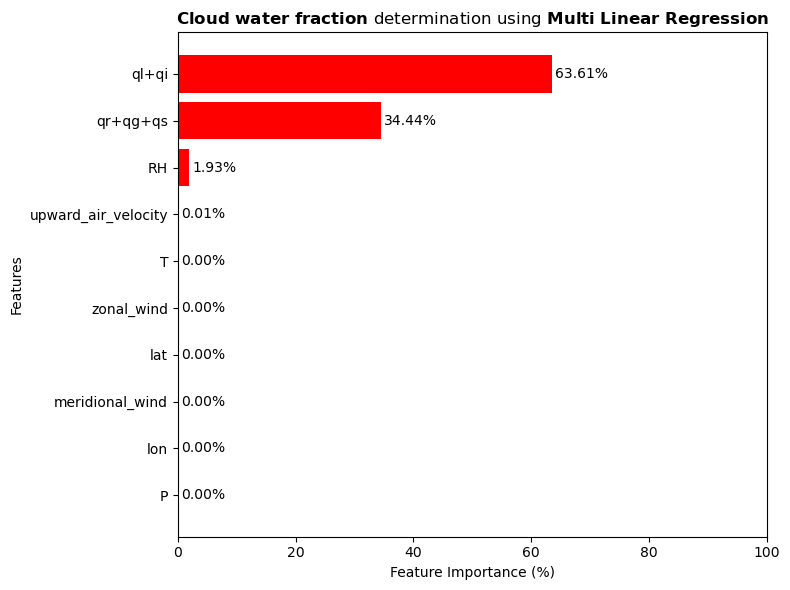

In [ ]:
#The relative importance of each variable can be determined after having standardised the variables.
# #Feature importance: MLR (without standardization)

# pairs = [(name, abs(coef)) for name, coef in zip(feature_names, coef_list)]
# total = sum(c for _, c in pairs)

# #Sort by importance (descending)
# pairs.sort(key=lambda x: x[1], reverse=True)

# names = []
# importances = []

# for name, coef in pairs:
#     pct = (coef / total) * 100
#     names.append(name)
#     importances.append(pct)
#     print(f"{name}: {pct:.4f} %")

# #Bar plot
# plt.figure(figsize=(8, 6))
# bars = plt.barh(names, importances, color="red")

# plt.xlabel("Feature Importance (%)")
# plt.ylabel("Features")

# #Modify title accordingly
# plt.title(r"$\mathbf{Cloud\ water\ fraction}$ determination using $\mathbf{Multi\ Linear\ Regression}$")

# # Highest importance at the top
# plt.gca().invert_yaxis()

# # Add percentage labels at the end of bars
# for bar in bars:
#     width = bar.get_width()
#     y = bar.get_y() + bar.get_height() / 2
#     plt.text(
#         width + 0.5,        #small space after the bar
#         y,
#         f"{width:.2f}%",
#         va="center"
#     )

# plt.xlim(0, 100)
# plt.tight_layout()
# plt.show()


In [13]:
#The following 'best' parameter values have been approximated from the values otained from the previous runs to find the closest best parameters in different datasets

# best_parameters= grid_search.best_params_
best_n_estimators=100 #best_parameters['n_estimators']
best_min_child_weight=30 #best_parameters['min_child_weight']
best_min_samples_leaf=30 
best_max_depth=10 #best_parameters['max_depth']
best_learning_rate=0.1 #best_parameters['learning_rate']


In [14]:
#Train using a Decision Tree Regressor
dec_tree_regressor = DTR(max_depth=best_max_depth, min_samples_leaf=best_min_samples_leaf, random_state=0) 

#Training
training_start_time = time.time()
dec_tree_regressor.fit(X_train, y_train)
training_end_time = time.time()
training_elapsed_time = training_end_time - training_start_time
print(f"Training- Elapsed time: {training_elapsed_time/60:.4f} minutes")

Training- Elapsed time: 1.5544 minutes


RH: 99.8000 %
ql+qi: 0.0934 %
T: 0.0761 %
qr+qg+qs: 0.0155 %
upward_air_velocity: 0.0063 %
lat: 0.0058 %
P: 0.0018 %
meridional_wind: 0.0006 %
zonal_wind: 0.0006 %
lon: 0.0000 %


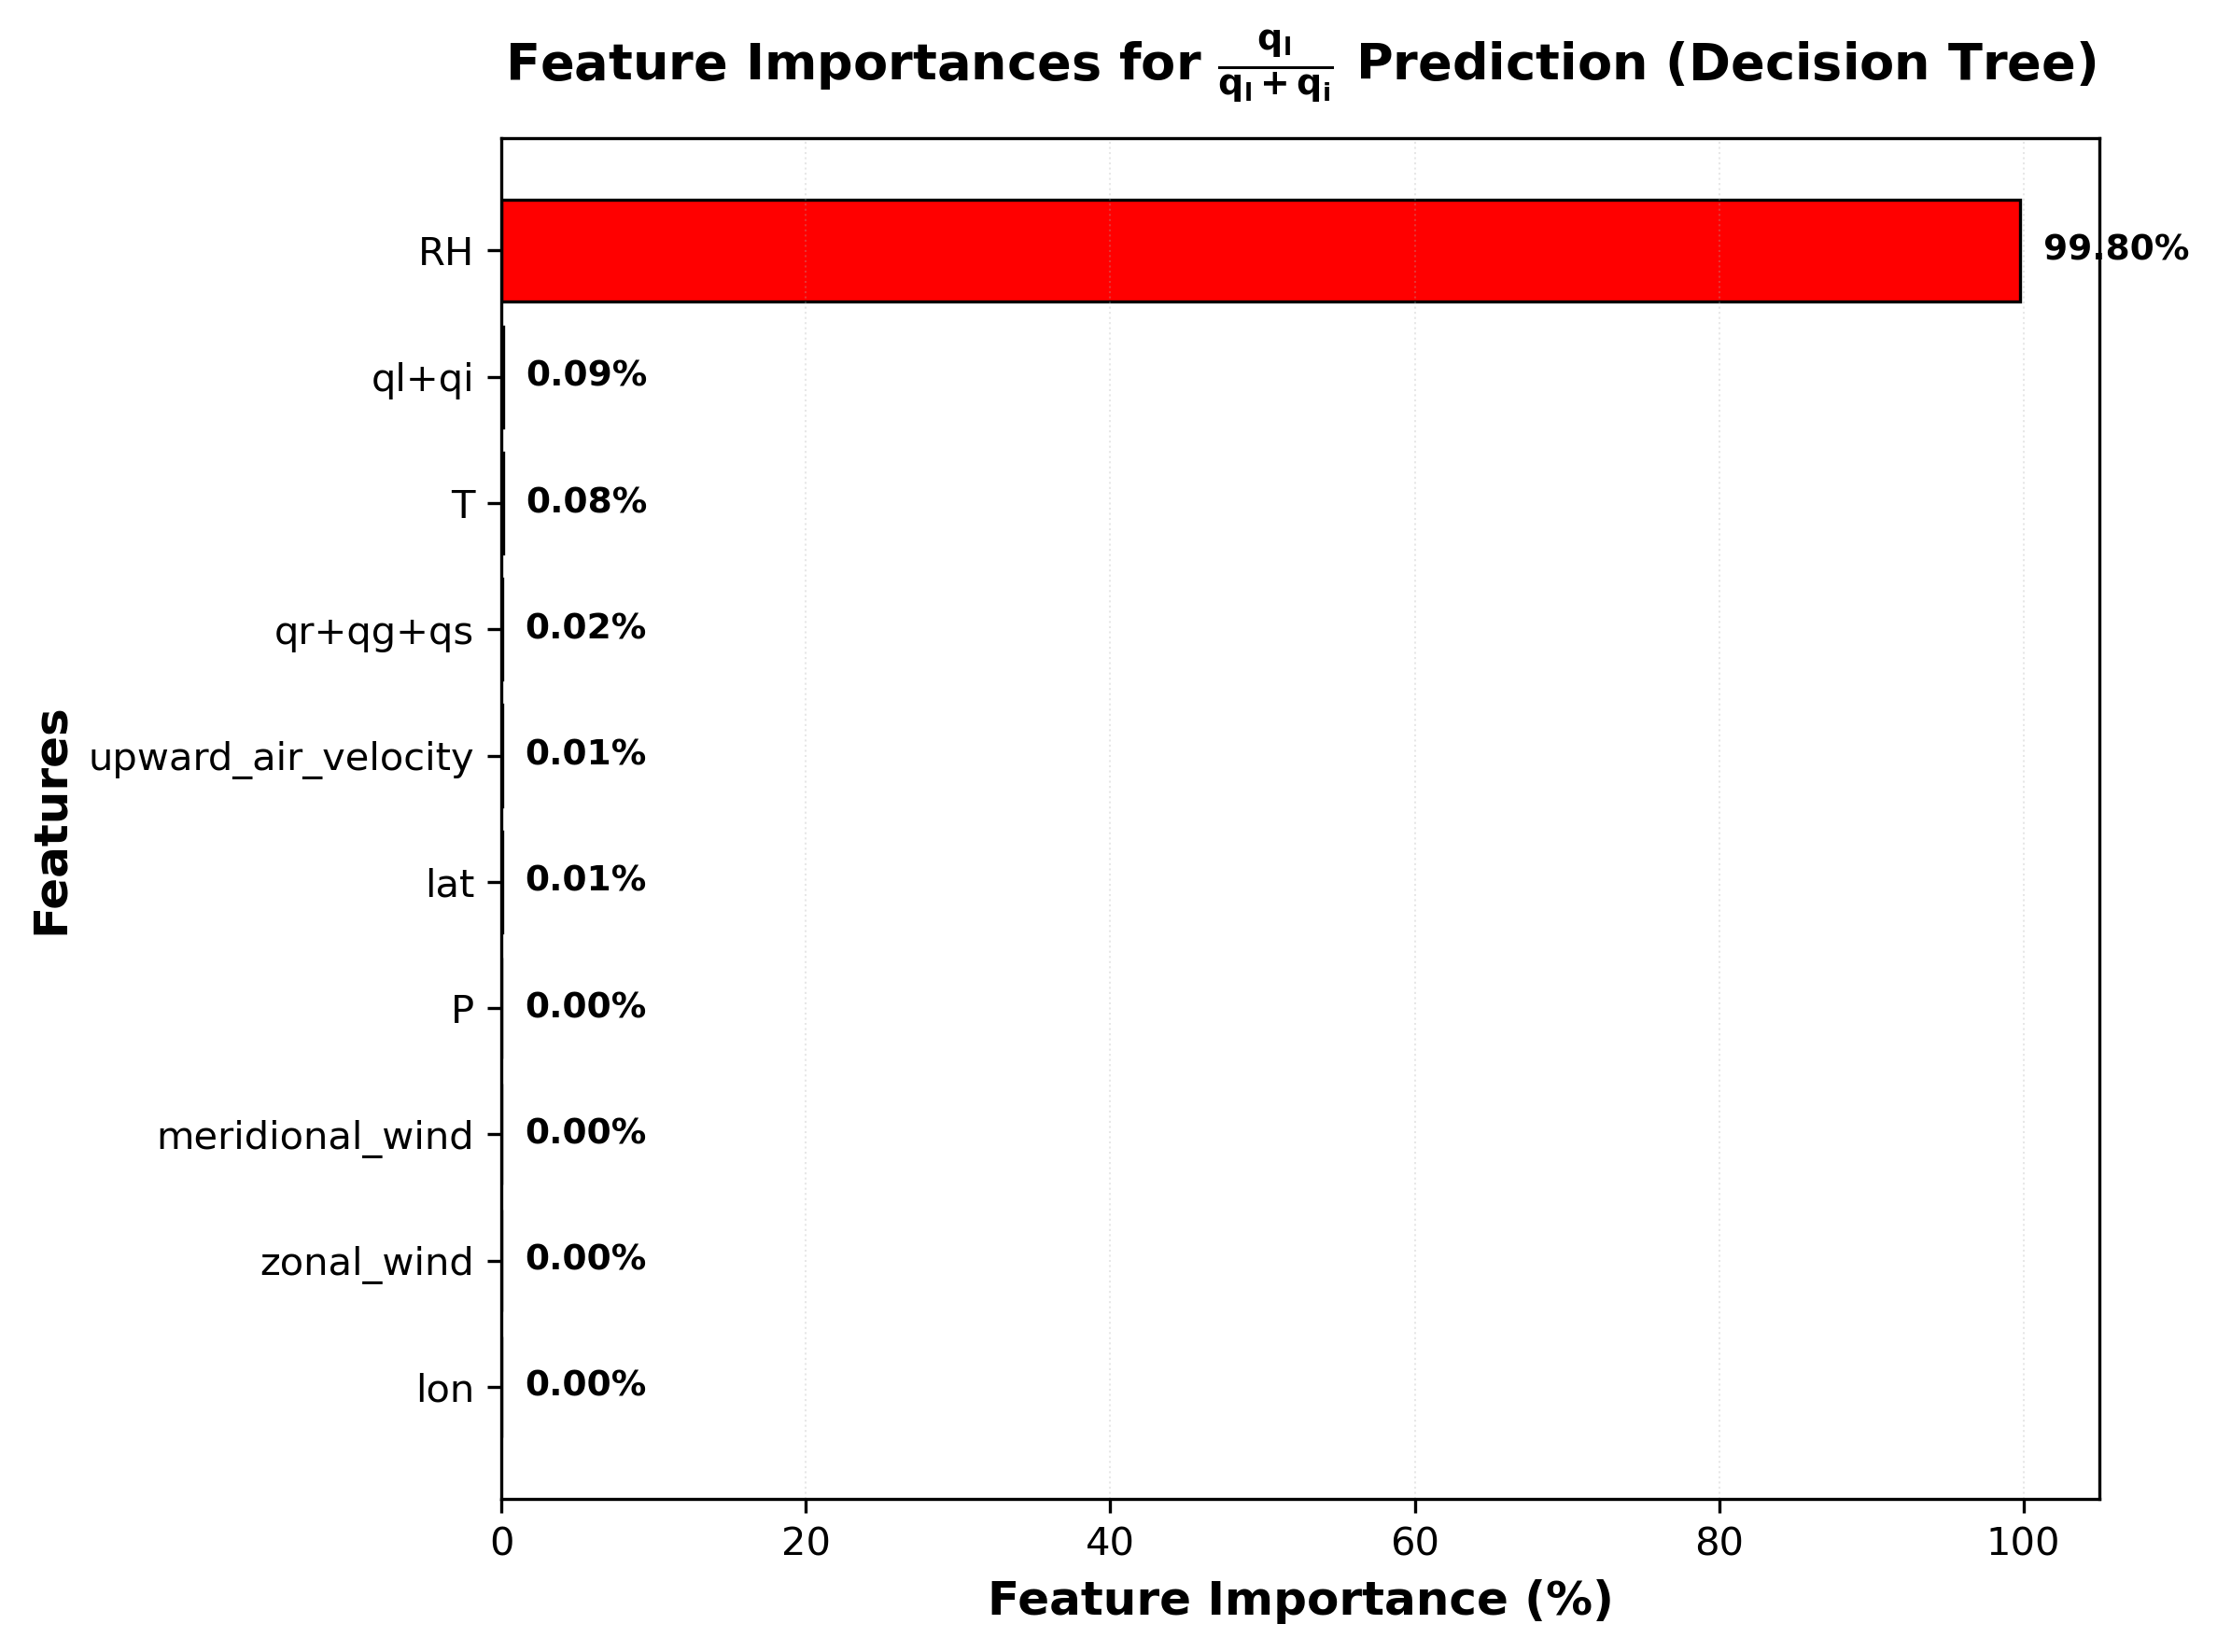

In [15]:
#Feature importance plot of the trained Decision Tree Regressor
importance = dec_tree_regressor.feature_importances_

#Combine feature names and scores
feature_scores = list(zip(feature_names, importance))

#Sort by score in descending order
feature_scores.sort(key=lambda x: x[1], reverse=True)

#Convert to percentages
names = []
importances = []

for name, score in feature_scores:
    pct = score * 100
    names.append(name)
    importances.append(pct)
    print(f"{name}: {pct:.4f} %")

fig, ax = plt.subplots(figsize=(8, 6), dpi=300)

bars = ax.barh(names, importances, color='red', edgecolor='black', linewidth=0.8)


ax.set_xlabel("Feature Importance (%)", fontsize=12, fontweight='bold')
ax.set_ylabel("Features", fontsize=12, fontweight='bold')
#ax.set_title(r"XGBoost Feature Importance: Ice-Phase Hydrometeor Fraction $\mathbf{\left(\frac{q_g}{q_s + q_g}\right)}$", 
ax.set_title(r"Feature Importances for $\mathbf{\frac{q_l}{q_l +q_i}}$ Prediction (Decision Tree)", 
            fontsize=13, fontweight='bold', pad=15)

ax.invert_yaxis() #Highest importance at the top

#Add percentage values on bars
for bar in bars:
    width = bar.get_width()
    y = bar.get_y() + bar.get_height() / 2
    ax.text(
        width + 1.5,
        y,
        f"{width:.2f}%",
        va="center",
        fontsize=9,
        fontweight='bold'
    )
ax.set_xlim(0, 105)

ax.grid(True, axis='x', alpha=0.3, linestyle=':', linewidth=0.5, zorder=0)

plt.tight_layout()
plt.savefig(f"../output/{output_folder_name}/FeatureImportance_DecisionTree.png",
    dpi=300, bbox_inches='tight')

plt.show()


In [16]:
#Train using Bagging
bagging_regressor = RandomForestRegressor(n_jobs=-1, random_state=0, max_depth=best_max_depth, min_samples_leaf=best_min_samples_leaf, n_estimators=best_n_estimators, oob_score=True)

#Training
training_start_time = time.time()
bagging_regressor.fit(X_train, y_train)
training_end_time = time.time()
training_elapsed_time = training_end_time - training_start_time
print(f"Training- Elapsed time: {training_elapsed_time/60:.4f} minutes")

Training- Elapsed time: 4.8723 minutes


RH: 99.7922 %
ql+qi: 0.0927 %
T: 0.0782 %
qr+qg+qs: 0.0195 %
lat: 0.0072 %
upward_air_velocity: 0.0060 %
P: 0.0024 %
meridional_wind: 0.0008 %
lon: 0.0007 %
zonal_wind: 0.0004 %


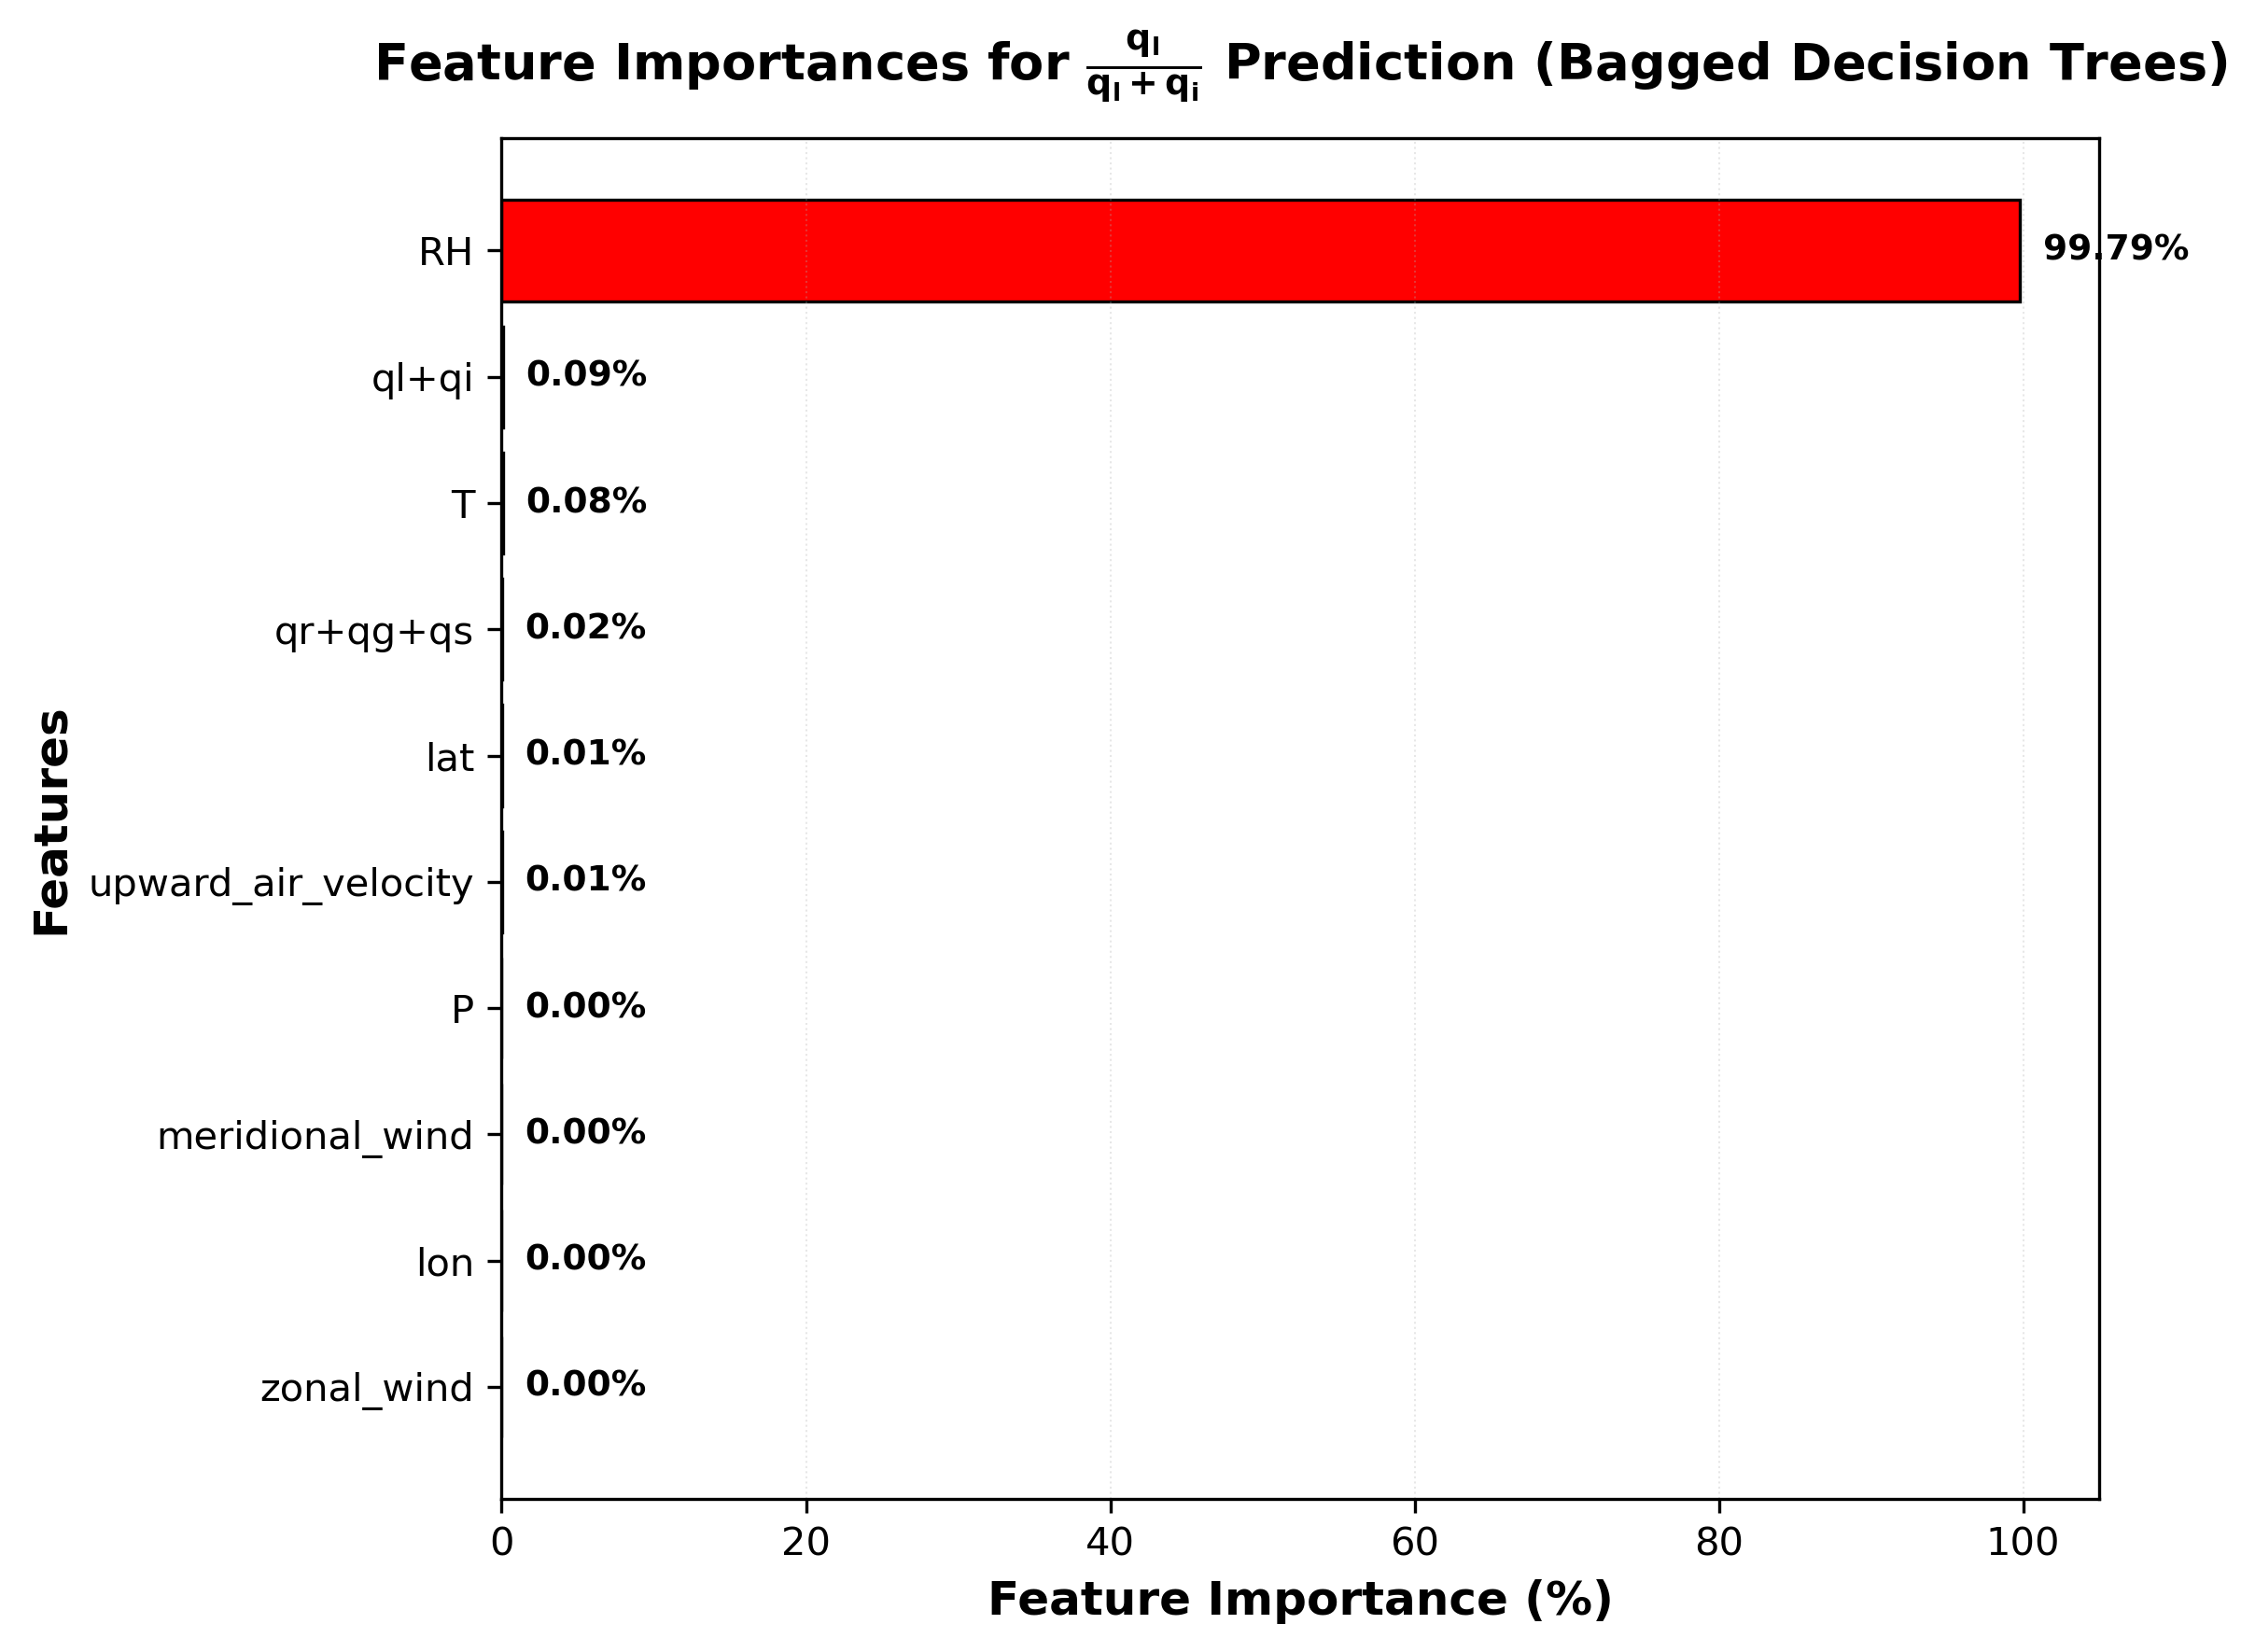

In [17]:
#Feature importance plot of the trained Bagged Decision Trees Regressor
importance = bagging_regressor.feature_importances_

#Combine feature names and scores
feature_scores = list(zip(feature_names, importance))

#Sort by score in descending order
feature_scores.sort(key=lambda x: x[1], reverse=True)

#Convert to percentages
names = []
importances = []

for name, score in feature_scores:
    pct = score * 100
    names.append(name)
    importances.append(pct)
    print(f"{name}: {pct:.4f} %")

fig, ax = plt.subplots(figsize=(8, 6), dpi=300)

bars = ax.barh(names, importances, color='red', edgecolor='black', linewidth=0.8)


ax.set_xlabel("Feature Importance (%)", fontsize=12, fontweight='bold')
ax.set_ylabel("Features", fontsize=12, fontweight='bold')
#ax.set_title(r"XGBoost Feature Importance: Ice-Phase Hydrometeor Fraction $\mathbf{\left(\frac{q_g}{q_s + q_g}\right)}$", 
ax.set_title(r"Feature Importances for $\mathbf{\frac{q_l}{q_l +q_i}}$ Prediction (Bagged Decision Trees)", 
            fontsize=13, fontweight='bold', pad=15)

ax.invert_yaxis() #Highest importance at the top

#Add percentage values on bars
for bar in bars:
    width = bar.get_width()
    y = bar.get_y() + bar.get_height() / 2
    ax.text(
        width + 1.5,
        y,
        f"{width:.2f}%",
        va="center",
        fontsize=9,
        fontweight='bold'
    )
ax.set_xlim(0, 105)

ax.grid(True, axis='x', alpha=0.3, linestyle=':', linewidth=0.5, zorder=0)

plt.tight_layout()
plt.savefig(f"../output/{output_folder_name}/FeatureImportance_BaggedDecisionTrees.png",
    dpi=300, bbox_inches='tight')

plt.show()


In [18]:
#Train using Random Forest
RF_regressor = RandomForestRegressor(n_estimators=best_n_estimators, max_features=int(np.sqrt(X_train.shape[1])), n_jobs=-1, random_state=0, max_depth=best_max_depth, min_samples_leaf=best_min_samples_leaf, oob_score=True)
#Training
training_start_time = time.time()
RF_regressor.fit(X_train, y_train)
training_end_time = time.time()
training_elapsed_time = training_end_time - training_start_time
print(f"Training- Elapsed time: {training_elapsed_time/60:.4f} minutes")



Training- Elapsed time: 2.3582 minutes


RH: 48.0268 %
T: 27.5692 %
P: 19.9069 %
zonal_wind: 2.2499 %
ql+qi: 0.9105 %
lat: 0.8932 %
meridional_wind: 0.2462 %
upward_air_velocity: 0.1243 %
qr+qg+qs: 0.0396 %
lon: 0.0334 %


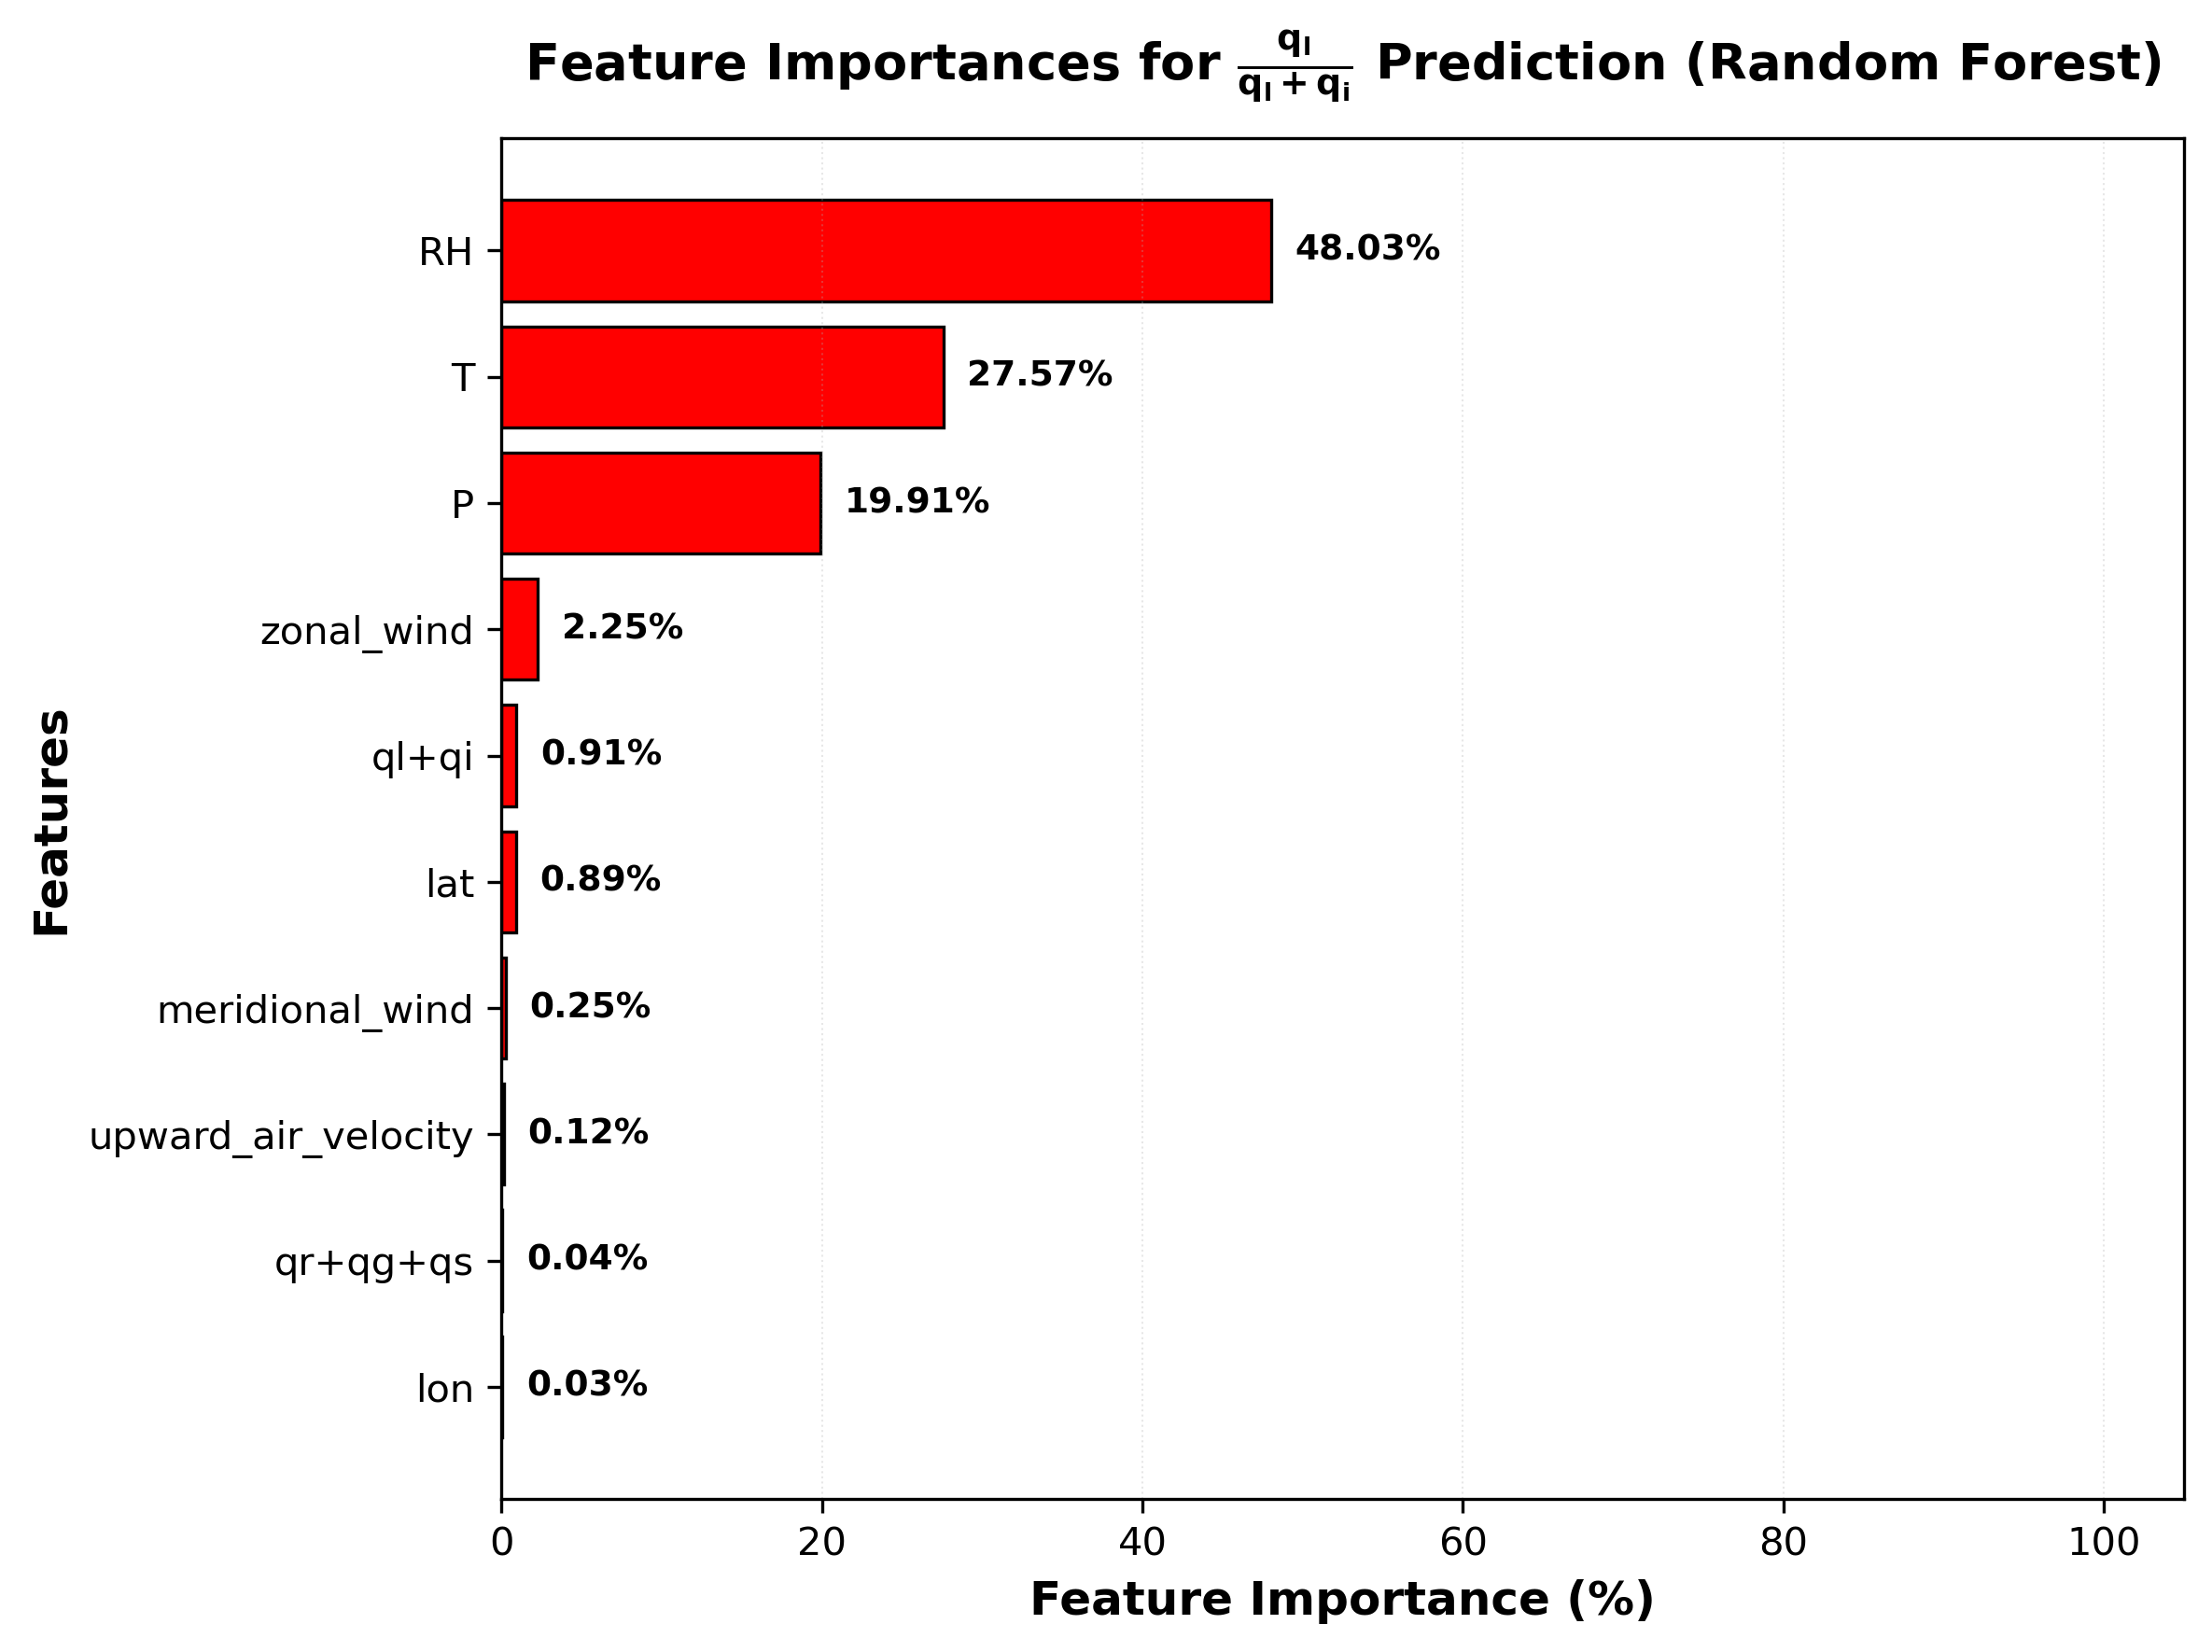

In [19]:
#Feature importance plot of the trained Random Forest Regressor
importance = RF_regressor.feature_importances_

#Combine feature names and scores
feature_scores = list(zip(feature_names, importance))

#Sort by score in descending order
feature_scores.sort(key=lambda x: x[1], reverse=True)

#Convert to percentages
names = []
importances = []

for name, score in feature_scores:
    pct = score * 100
    names.append(name)
    importances.append(pct)
    print(f"{name}: {pct:.4f} %")

fig, ax = plt.subplots(figsize=(8, 6), dpi=300)

bars = ax.barh(names, importances, color='red', edgecolor='black', linewidth=0.8)


ax.set_xlabel("Feature Importance (%)", fontsize=12, fontweight='bold')
ax.set_ylabel("Features", fontsize=12, fontweight='bold')
#ax.set_title(r"XGBoost Feature Importance: Ice-Phase Hydrometeor Fraction $\mathbf{\left(\frac{q_g}{q_s + q_g}\right)}$", 
ax.set_title(r"Feature Importances for $\mathbf{\frac{q_l}{q_l +q_i}}$ Prediction (Random Forest)", 
            fontsize=13, fontweight='bold', pad=15)

ax.invert_yaxis() #Highest importance at the top

#Add percentage values on bars
for bar in bars:
    width = bar.get_width()
    y = bar.get_y() + bar.get_height() / 2
    ax.text(
        width + 1.5,
        y,
        f"{width:.2f}%",
        va="center",
        fontsize=9,
        fontweight='bold'
    )
ax.set_xlim(0, 105)

ax.grid(True, axis='x', alpha=0.3, linestyle=':', linewidth=0.5, zorder=0)

plt.tight_layout()
plt.savefig(f"../output/{output_folder_name}/FeatureImportance_RandomForest.png",
    dpi=300, bbox_inches='tight')

plt.show()


In [20]:
#Train using xgb
xgb_model = XGBRegressor(n_estimators=best_n_estimators, min_child_weight= best_min_child_weight, max_depth=best_max_depth, learning_rate=best_learning_rate, n_jobs=-1, random_state=0) #verbosity=3 (optional)

##Training
training_start_time = time.time()
xgb_model.fit(X_train, y_train)
training_end_time = time.time()
training_elapsed_time = training_end_time - training_start_time
print(f"Training- Elapsed time: {training_elapsed_time/60:.4f} minutes")

joblib.dump(xgb_model, os.path.join('../output', output_folder_name, 'xgb_model_ql_by_(ql+qi)_using_all_locals'))
xgb_model=joblib.load(os.path.join('../output', output_folder_name, 'xgb_model_ql_by_(ql+qi)_using_all_locals'))

Training- Elapsed time: 0.3262 minutes


RH: 99.8559 %
T: 0.0504 %
ql+qi: 0.0407 %
qr+qg+qs: 0.0163 %
upward_air_velocity: 0.0089 %
P: 0.0072 %
lat: 0.0065 %
meridional_wind: 0.0051 %
zonal_wind: 0.0045 %
lon: 0.0044 %


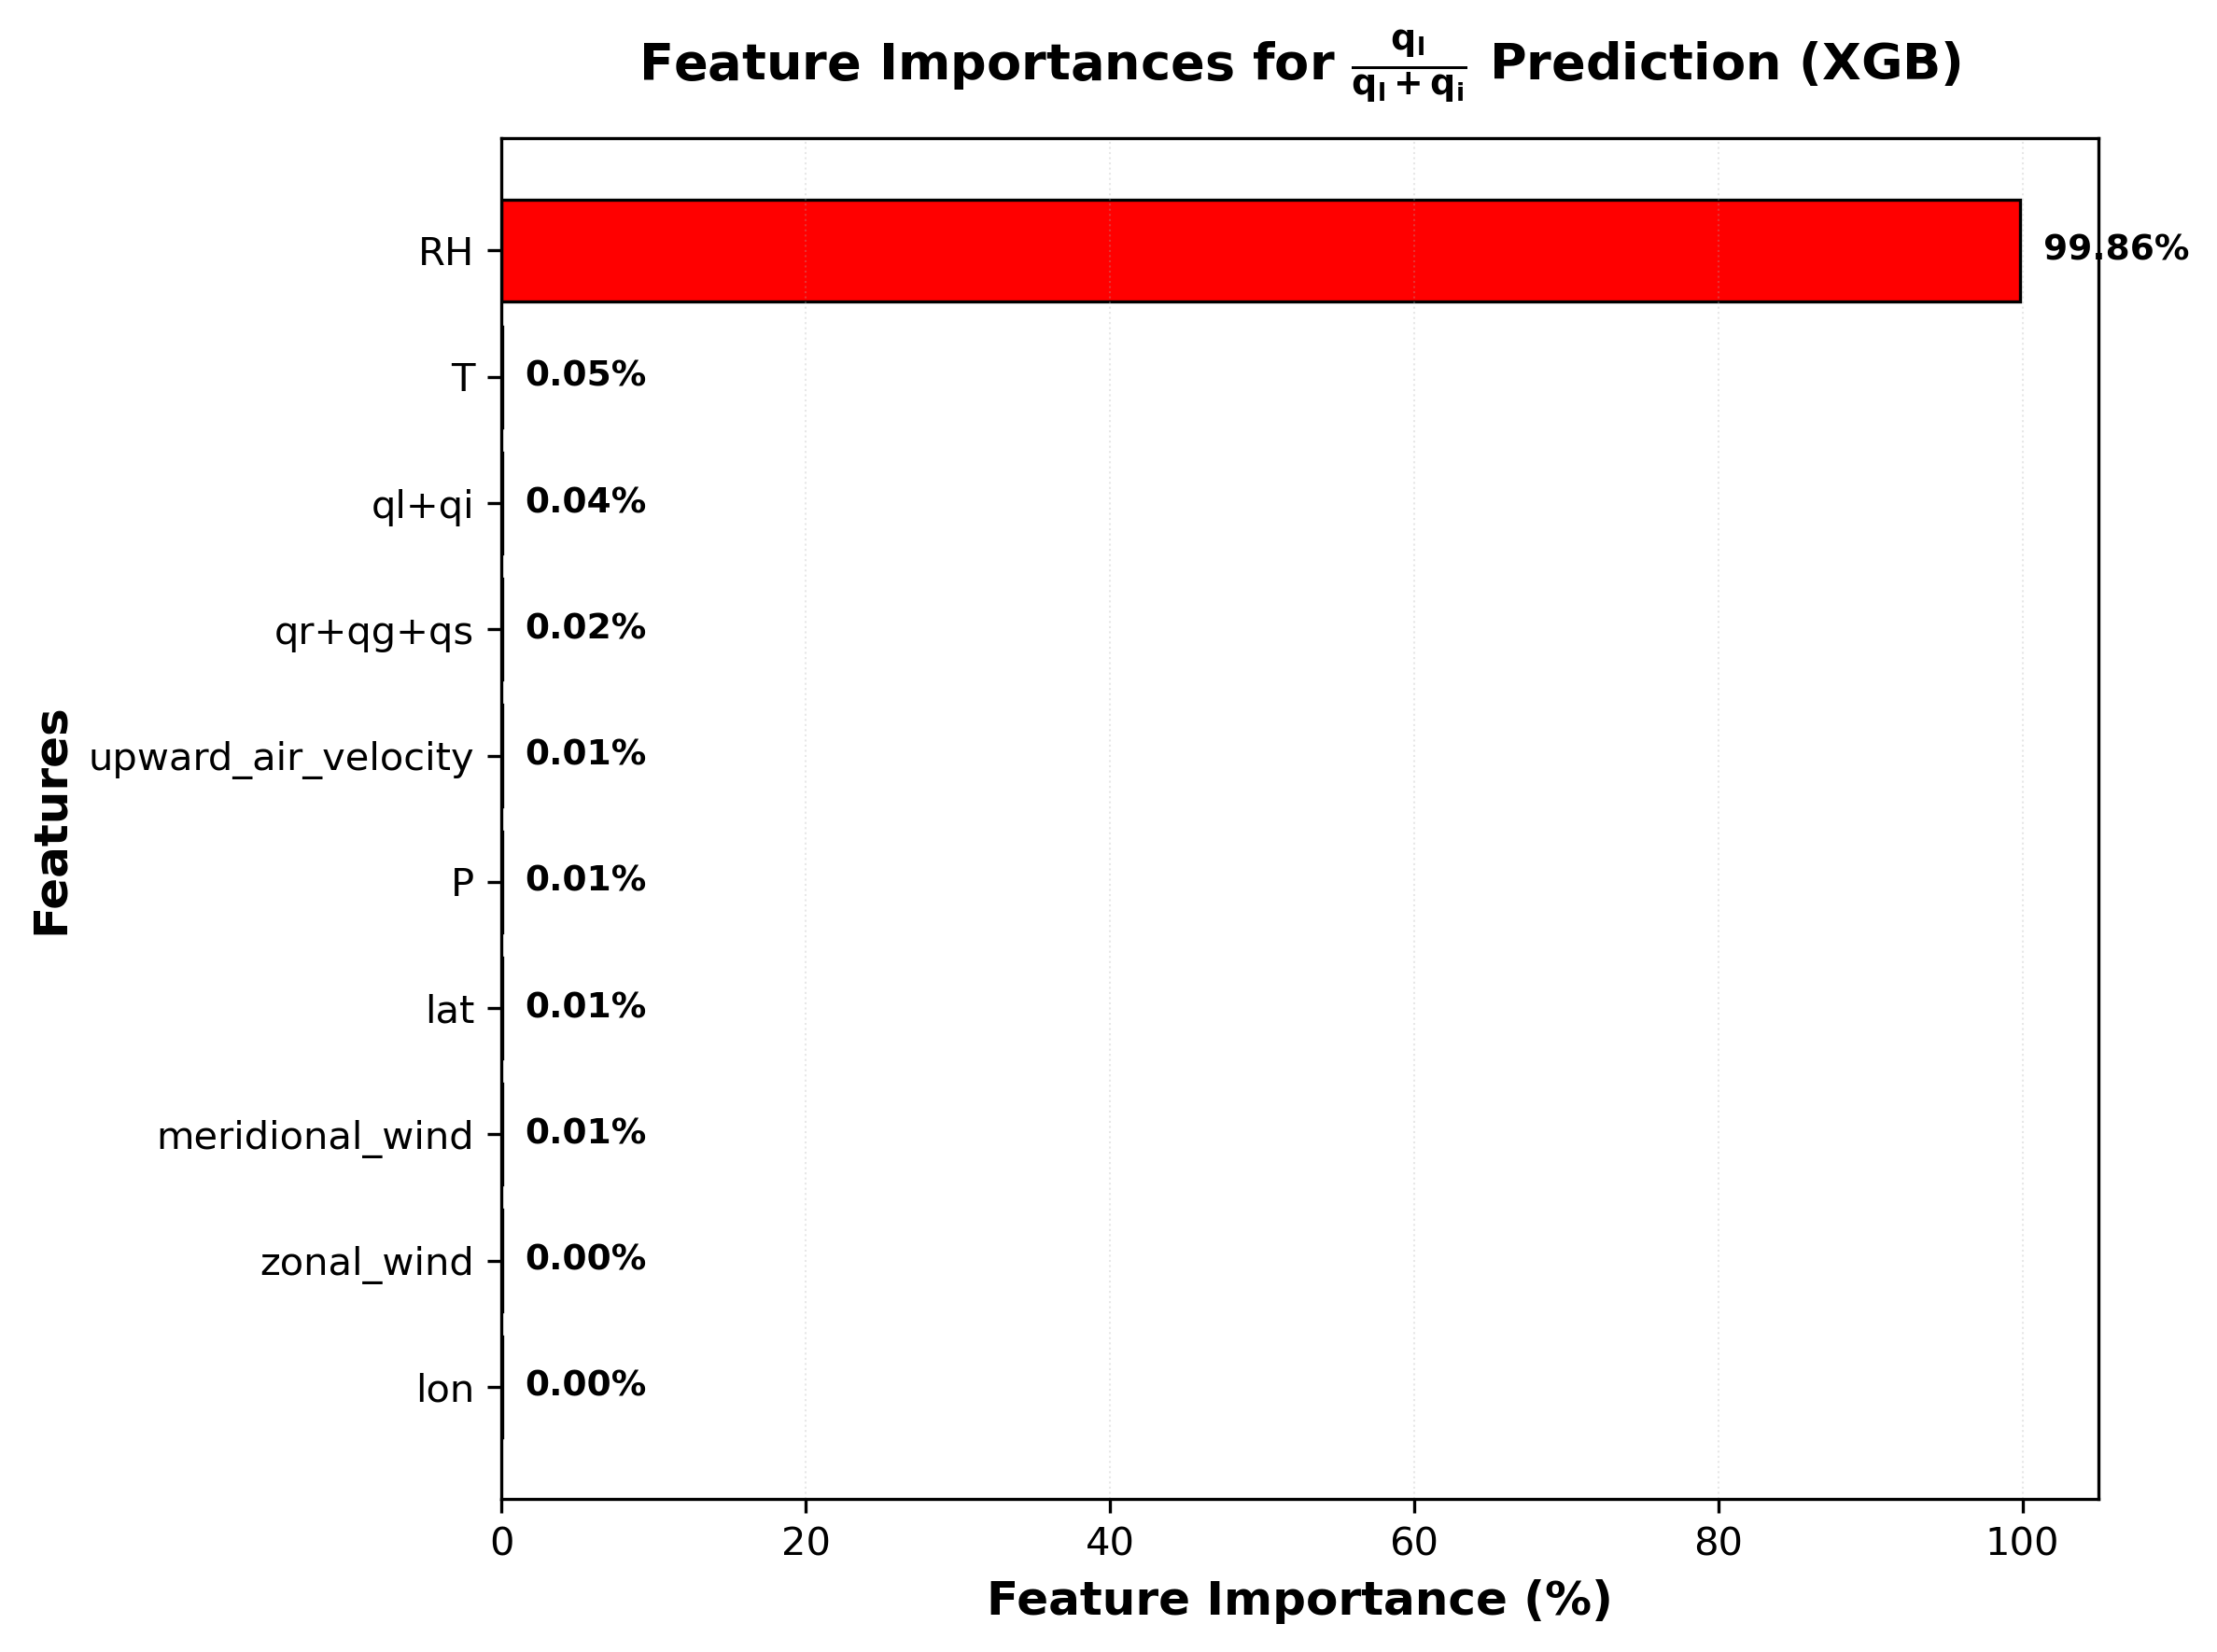

In [21]:
#Feature importance plot of the trained xgb model
importance = xgb_model.feature_importances_

#Combine feature names and scores
feature_scores = list(zip(feature_names, importance))

#Sort by score in descending order
feature_scores.sort(key=lambda x: x[1], reverse=True)

#Convert to percentages
names = []
importances = []

for name, score in feature_scores:
    pct = score * 100
    names.append(name)
    importances.append(pct)
    print(f"{name}: {pct:.4f} %")

fig, ax = plt.subplots(figsize=(8, 6), dpi=300)

bars = ax.barh(names, importances, color='red', edgecolor='black', linewidth=0.8)


ax.set_xlabel("Feature Importance (%)", fontsize=12, fontweight='bold')
ax.set_ylabel("Features", fontsize=12, fontweight='bold')
#ax.set_title(r"XGBoost Feature Importance: Ice-Phase Hydrometeor Fraction $\mathbf{\left(\frac{q_g}{q_s + q_g}\right)}$", 
ax.set_title(r"Feature Importances for $\mathbf{\frac{q_l}{q_l +q_i}}$ Prediction (XGB)", 
            fontsize=13, fontweight='bold', pad=15)

ax.invert_yaxis() #Highest importance at the top

#Add percentage values on bars
for bar in bars:
    width = bar.get_width()
    y = bar.get_y() + bar.get_height() / 2
    ax.text(
        width + 1.5,
        y,
        f"{width:.2f}%",
        va="center",
        fontsize=9,
        fontweight='bold'
    )
ax.set_xlim(0, 105)

ax.grid(True, axis='x', alpha=0.3, linestyle=':', linewidth=0.5, zorder=0)

plt.tight_layout()
plt.savefig(f"../output/{output_folder_name}/FeatureImportance_XGB.png",
    dpi=300, bbox_inches='tight')

plt.show()


In [22]:
#Preprocessing test ds_test
#subset of the original dataset
seed = 1
# sample_frac = 0.001
ht=31
data=ds_test.sel(height=ht, height_2=ht) 

total = data['ql'] + data['qi']
data['ql/(ql+qi)'] = data['ql'].where(total != 0, 0) / total.where(total != 0, 1)
data['qi/(ql+qi)'] = data['qi'].where(total != 0, 0) / total.where(total != 0, 1)

total_precipitates = data['qr'] + data['qs']+ data['qg']
data['qr/(qr+qs+qg)'] = data['qr'].where(total_precipitates != 0, 0) / total_precipitates.where(total_precipitates != 0, 1)
data['qs/(qr+qs+qg)'] = data['qs'].where(total_precipitates != 0, 0) / total_precipitates.where(total_precipitates != 0, 1)
data['qg/(qr+qs+qg)'] = data['qg'].where(total_precipitates != 0, 0) / total_precipitates.where(total_precipitates != 0, 1)

df_test = data.to_dataframe() #.sample(frac=1, random_state=seed) #frac=sample_frac

#threshold
threshold = 5e-12
df_test_new = df_test[(df_test['ql'] + df_test['qi'] + df_test['qr'] + df_test['qg'] + df_test['qs']) >= threshold]

if df_test_new.empty:
    df_test_new = df_test

df_test = df_test_new
# df_test = data.to_dataframe().sample(frac=sample_frac, random_state=seed)

df_tests = [df_test]  
# for ht in range(32, 91, 5): #(32, 91, 5)
for ht in range(36, 91, 5): #(44, 91, 4)
    data = ds_test.sel(height=ht, height_2=ht)
    #Graupel Threshold set to 1e-6 kg/kg as mentioned in Michibata, 2024
    # data = data.where(data['qg'] >= 1e-6)

    total = data['ql'] + data['qi']
    data['ql/(ql+qi)'] = data['ql'].where(total != 0, 0) / total.where(total != 0, 1)
    data['qi/(ql+qi)'] = data['qi'].where(total != 0, 0) / total.where(total != 0, 1)

    total_precipitates = data['qr'] + data['qs']+ data['qg']
    data['qr/(qr+qs+qg)'] = data['qr'].where(total_precipitates != 0, 0) / total_precipitates.where(total_precipitates != 0, 1)
    data['qs/(qr+qs+qg)'] = data['qs'].where(total_precipitates != 0, 0) / total_precipitates.where(total_precipitates != 0, 1)
    data['qg/(qr+qs+qg)'] = data['qg'].where(total_precipitates != 0, 0) / total_precipitates.where(total_precipitates != 0, 1)

    df_test_sampled=data.to_dataframe() #.sample(frac=1, random_state= seed+ht) #frac=sample_frac

    #threshold
    threshold = 5e-12
    df_test_sampled_new = df_test_sampled[(df_test_sampled['ql'] + df_test_sampled['qi'] + df_test_sampled['qr'] + df_test_sampled['qg'] + df_test_sampled['qs']) >= threshold]

    if df_test_sampled_new.empty:
        df_test_sampled_new = df_test_sampled

    df_test_sampled = df_test_sampled_new

    df_tests.append(df_test_sampled) 


    print(f"Last value of clon in df_test with height {ht} is", df_test_sampled['clon'].iloc[-1])

df_test = pd.concat(df_tests, ignore_index=True)

expected_length = sum(len(x) for x in df_tests)
print("Expected length of df_test: ", expected_length)
print('Final length of df_test: ', len(df_test))

#OBtain lon and lat from clon and clat respectively
df_test['lon'] = df_test['clon']*180/np.pi #in degrees
df_test['lat'] = df_test['clat']*180/np.pi #in degrees

#RH data
# df_test['RH']=RH_from_SH(df_test['P'], df_test['SH'], df_test['T'])
df_test['RH'] = thermodynamics.relative_humidity_water(df_test['SH'], df_test['T'], df_test['air_density'])

count=0
for i in df_test['RH']:
    if i>100 or i<0:
        count+=1
print("RH out-of-range count = ", count)
print("RH out-of-range count percent = ", 100*count/len(df_test['RH']), " %")

df_test['RH']= df_test['RH'].clip(lower=0, upper=100)

#Insert variables to the df_test
col=df_test.pop('RH')
df_test.insert(16, 'RH', col) #SH is at 15th position
#df_test.pop('SH')

df_test['ql+qi']=df_test['ql']+df_test['qi']
col=df_test.pop('ql+qi')
df_test.insert(26, 'ql+qi', col) 

#Include 'cloud liquid water path + cloud ice path' as a feature.
df_test['CLWP+CIP']=df_test['CLWP']+df_test['CIP']
col=df_test.pop('CLWP+CIP')
df_test.insert(27, 'CLWP+CIP', col) 

#Adding another column; qr+qg+qs and use it later as an input feature
df_test['qr+qg+qs'] = df_test['qr'] + df_test['qg'] + df_test['qs']
col=df_test.pop('qr+qg+qs')
df_test.insert(30, 'qr+qg+qs', col)

# df_test['ql/(ql+qi)'] = df_test['ql'] / (df_test['ql']+ df_test['qi']) 
# print('Number of NaN values in qr/(qr+qs+qg) column: ', df_test['ql/(ql+qi)'].isna().sum())
# df_test = df_test.dropna(subset=['ql/(ql+qi)'])
# print('Number of NaN values in qr/(qr+qs+qg) column now: ', df_test['ql/(ql+qi)'].isna().sum())

#mass-weighted condensates
# df_test['m_ci']=df_test['dzghalf']*df_test['air_density']*df_test['cell_area']* (df_test['ql']+df_test['qi'])
# col=df_test.pop('m_ci')
# df_test.insert(28, 'm_ci', col) 

# #mass-weighted random sampling
# df_test['m_rsg']=df_test['dzghalf']*df_test['air_density']*df_test['cell_area']* (df_test['qr']+df_test['qs']+df_test['qg'])
# col=df_test.pop('m_rsg')
# df_test.insert(28, 'm_rsg', col) 

# df_test = df_test.sort_values(by='m_ci', ascending=False)
# df_test = df_test.reset_index(drop=True)

# total_mass = df_test['m_ci'].sum()
# df_test['cum_mass'] = df_test['m_ci'].cumsum()
# col=df_test.pop('cum_mass')
# df_test.insert(29, 'cum_mass', col) 

# n_samples= int(np.floor(len(df_test) * 0.1)) #we are taking a way smaller dataset because of this 
# n_samples= int(np.floor(len(df_test))) 
# np.random.seed(29)
# random_values = np.random.uniform(0, df_test['cum_mass'].max(), size=n_samples)
# print('Random values: ', random_values)
# # indices= np.searchsorted(df_test['cum_mass'].values, random_values)
# indices = np.clip(np.searchsorted(df_test['cum_mass'].values, random_values), 0, len(df_test) - 1)
# df_test_orig=df_test
# df_test = df_test.iloc[indices].reset_index(drop=True)


Last value of clon in df_test with height 36 is 2.0357769087179167
Last value of clon in df_test with height 41 is 1.901982962125632
Last value of clon in df_test with height 46 is 0.956579968688332
Last value of clon in df_test with height 51 is 1.3317619703945918
Last value of clon in df_test with height 56 is 1.3343108942333097
Last value of clon in df_test with height 61 is 1.3343108942333097
Last value of clon in df_test with height 66 is 1.3085211399396937
Last value of clon in df_test with height 71 is 1.3053725942366794
Last value of clon in df_test with height 76 is 1.294027607905691
Last value of clon in df_test with height 81 is 1.3343108942333097
Last value of clon in df_test with height 86 is 1.3343108942333097
Expected length of df_test:  58141682
Final length of df_test:  58141682
RH out-of-range count =  0
RH out-of-range count percent =  0.0  %


In [23]:
X_test = df_test[feature_names] 
y_test = df_test['ql/(ql+qi)'].values 

In [24]:
#weight parameter
df_test_final= df_test.loc[X_test.index]
weight = df_test_final['cell_area']*df_test_final['dzghalf']*df_test_final['air_density']*(df_test_final['ql'] + df_test_final['qi']) 

#total weights of the hydrometeors in the test dataset
total_weight_cloud_liquid_water = (df_test_final['cell_area']*df_test_final['dzghalf']*df_test_final['air_density']*(df_test_final['ql'])).sum()
total_weight_cloud_ice = (df_test_final['cell_area']*df_test_final['dzghalf']*df_test_final['air_density']*(df_test_final['qi'])).sum() 
total_weight_rain = (df_test_final['cell_area']*df_test_final['dzghalf']*df_test_final['air_density']*(df_test_final['qr'])).sum() 
total_weight_snow = (df_test_final['cell_area']*df_test_final['dzghalf']*df_test_final['air_density']*(df_test_final['qs'])).sum() 
total_weight_graupel = (df_test_final['cell_area']*df_test_final['dzghalf']*df_test_final['air_density']*(df_test_final['qg'])).sum() 

print(f"{total_weight_cloud_liquid_water:.4e}, {total_weight_cloud_ice:.4e}, {total_weight_rain:.4e}, {total_weight_snow:.4e}, {total_weight_graupel:.4e}")

7.1953e+12, 1.2094e+12, 1.8382e+12, 3.2225e+12, 8.0213e+11


In [25]:
#Multilinear Regressor Prediction
prediction_start_time = time.time()
y_predicted = regr.predict(X_test)
prediction_end_time = time.time()
prediction_elapsed_time = prediction_end_time - prediction_start_time
print(f"Prediction- Elapsed time: {prediction_elapsed_time/60:.4f} minutes")


print("min:", np.min(y_predicted))
print("max:", np.max(y_predicted))
y_predicted = np.clip(y_predicted, 0, 1)

#Error Analysis on TEST data
#MSE_test
mse_TEST= np.mean((y_test- y_predicted)**2)
print(f'MSE_TEST: {mse_TEST}')

#rmse_test
rmse_TEST = np.sqrt(np.mean((y_test - y_predicted)**2))
print(f'RMSE_TEST: {rmse_TEST}')
# print(f'MSE_TEST: {(rmse_TEST)**2}')

#mae_TEST
mae_TEST = np.mean(abs(y_test - y_predicted))
print(f'mae_TEST: {mae_TEST}')

#R2_test_sklearn
r2_sklearn = r2_score(y_test, y_predicted)
print("R² score:", r2_sklearn)

#Weighted metrics
#weighted RMSE
weighted_mse_TEST = mean_squared_error(
    y_test,
    y_predicted,
    sample_weight=weight
)
weighted_rmse_TEST = np.sqrt(weighted_mse_TEST)
print(f"Weighted RMSE_TEST: {weighted_rmse_TEST}")

#Weighted MAE
weighted_mae_TEST = mean_absolute_error(
    y_test,
    y_predicted,
    sample_weight=weight
)
print(f"Weighted MAE_TEST: {weighted_mae_TEST}")

#weighted R^2
weighted_r2 = weighted_r_squared(y_test, y_predicted, weight, y_train)
print("Weighted R² score: ", weighted_r2)


Prediction- Elapsed time: 0.0383 minutes
min: -1.9151361182697406
max: 1.5009969884346464
MSE_TEST: 0.10880787132407924
RMSE_TEST: 0.32986038156177416
mae_TEST: 0.17608674973279584
R² score: -0.1944537880249788
Weighted RMSE_TEST: 0.11833705397617184
Weighted MAE_TEST: 0.051967188774254366
Weighted R² score:  0.8853077380630058


In [26]:
#Decision Tree Prediction
prediction_start_time = time.time()
y_pred = dec_tree_regressor.predict(X_test)
prediction_end_time = time.time()
prediction_elapsed_time = prediction_end_time - prediction_start_time
print(f"Prediction- Elapsed time: {prediction_elapsed_time/60:.4f} minutes")

print("max value of the fraction: ", np.max(y_pred))
print("min value of the fraction: ", np.min(y_pred))

count=0
for i in y_pred:
    if i>1 or i<0:
        # print(i)
        count+=1
print("Out-of-range count = ", count)
print("Out-of-range count percent = ", 100*count/len(y_pred) , " %")

y_pred = np.clip(y_pred, 0, 1)
# y_test=y_test.ravel()
# y_pred=y_pred.ravel()

#Error Analysis on TEST data
#mse
# mse= np.mean((y_test- y_pred)**2)
# print('MSE_Test: ', mse)

#rmse_test
rmse_TEST = np.sqrt(np.mean((y_test - y_pred)**2))
print(f'RMSE_TEST: {rmse_TEST}')

#mae_TEST
mae_TEST = np.mean(abs(y_test - y_pred))
print(f'mae_TEST: {mae_TEST}')

#R2_test_sklearn
r2_sklearn = r2_score(y_test, y_pred)
print("R² score: ", r2_sklearn)

###############
#weighted RMSE
weighted_mse_TEST = mean_squared_error(
    y_test,
    y_pred,
    sample_weight=weight
)
weighted_rmse_TEST = np.sqrt(weighted_mse_TEST)
print(f"Weighted RMSE_TEST: {weighted_rmse_TEST}")

#Weighted MAE
weighted_mae_TEST = mean_absolute_error(
    y_test,
    y_pred,
    sample_weight=weight
)
print(f"Weighted MAE_TEST: {weighted_mae_TEST}")

#weighted R^2
weighted_r2 = weighted_r_squared(y_test, y_pred, weight, y_train)
print("Weighted R² score: ", weighted_r2)

Prediction- Elapsed time: 0.0633 minutes
max value of the fraction:  0.9999999850650829
min value of the fraction:  0.0
Out-of-range count =  0
Out-of-range count percent =  0.0  %
RMSE_TEST: 0.01808565712371458
mae_TEST: 0.0012320397261094867
R² score:  0.9964093123817613
Weighted RMSE_TEST: 0.016806393461809822
Weighted MAE_TEST: 0.0015374716956307343
Weighted R² score:  0.9976866482936024


In [27]:
#Bagging Prediction
prediction_start_time = time.time()
y_pred = bagging_regressor.predict(X_test)
prediction_end_time = time.time()
prediction_elapsed_time = prediction_end_time - prediction_start_time
print(f"Prediction- Elapsed time: {prediction_elapsed_time/60:.4f} minutes")

print("max value of the fraction: ", np.max(y_pred))
print("min value of the fraction: ", np.min(y_pred))

count=0
for i in y_pred:
    if i>1 or i<0:
        # print(i)
        count+=1
print("Out-of-range count = ", count)
print("Out-of-range count percent = ", 100*count/len(y_pred) , " %")

y_pred = np.clip(y_pred, 0, 1)
# y_test=y_test.ravel()
# y_pred=y_pred.ravel()

#Error Analysis on TEST data
#mse
# mse= np.mean((y_test- y_pred)**2)
# print('MSE_Test: ', mse)

#rmse_test
rmse_TEST = np.sqrt(np.mean((y_test - y_pred)**2))
print(f'RMSE_TEST: {rmse_TEST}')

#mae_TEST
mae_TEST = np.mean(abs(y_test - y_pred))
print(f'mae_TEST: {mae_TEST}')

#R2_test_sklearn
r2_sklearn = r2_score(y_test, y_pred)
print("R² score: ", r2_sklearn)

###############
#weighted RMSE
weighted_mse_TEST = mean_squared_error(
    y_test,
    y_pred,
    sample_weight=weight
)
weighted_rmse_TEST = np.sqrt(weighted_mse_TEST)
print(f"Weighted RMSE_TEST: {weighted_rmse_TEST}")

#Weighted MAE
weighted_mae_TEST = mean_absolute_error(
    y_test,
    y_pred,
    sample_weight=weight
)
print(f"Weighted MAE_TEST: {weighted_mae_TEST}")

#weighted R^2
weighted_r2 = weighted_r_squared(y_test, y_pred, weight, y_train)
print("Weighted R² score: ", weighted_r2)

Prediction- Elapsed time: 0.2663 minutes
max value of the fraction:  0.9999999809875412
min value of the fraction:  0.0
Out-of-range count =  0
Out-of-range count percent =  0.0  %
RMSE_TEST: 0.01693246308011589
mae_TEST: 0.0011699986417371526
R² score:  0.9968526190436027
Weighted RMSE_TEST: 0.015757489865472426
Weighted MAE_TEST: 0.0014341805159539952
Weighted R² score:  0.9979663946095735


In [28]:
#RF Prediction
prediction_start_time = time.time()
y_pred = RF_regressor.predict(X_test)
prediction_end_time = time.time()
prediction_elapsed_time = prediction_end_time - prediction_start_time
print(f"Prediction- Elapsed time: {prediction_elapsed_time/60:.4f} minutes")

print("max value of the fraction: ", np.max(y_pred))
print("min value of the fraction: ", np.min(y_pred))

count=0
for i in y_pred:
    if i>1 or i<0:
        # print(i)
        count+=1
print("Out-of-range count = ", count)
print("Out-of-range count percent = ", 100*count/len(y_pred) , " %")

y_pred = np.clip(y_pred, 0, 1)
# y_test=y_test.ravel()
# y_pred=y_pred.ravel()

#Error Analysis on TEST data
#mse
# mse= np.mean((y_test- y_pred)**2)
# print('MSE_Test: ', mse)

#rmse_test
rmse_TEST = np.sqrt(np.mean((y_test - y_pred)**2))
print(f'RMSE_TEST: {rmse_TEST}')

#mae_TEST
mae_TEST = np.mean(abs(y_test - y_pred))
print(f'mae_TEST: {mae_TEST}')

#R2_test_sklearn
r2_sklearn = r2_score(y_test, y_pred)
print("R² score: ", r2_sklearn)

###############
#weighted RMSE
weighted_mse_TEST = mean_squared_error(
    y_test,
    y_pred,
    sample_weight=weight
)
weighted_rmse_TEST = np.sqrt(weighted_mse_TEST)
print(f"Weighted RMSE_TEST: {weighted_rmse_TEST}")

#Weighted MAE
weighted_mae_TEST = mean_absolute_error(
    y_test,
    y_pred,
    sample_weight=weight
)
print(f"Weighted MAE_TEST: {weighted_mae_TEST}")

#weighted R^2
weighted_r2 = weighted_r_squared(y_test, y_pred, weight, y_train)
print("Weighted R² score: ", weighted_r2)

Prediction- Elapsed time: 0.2670 minutes
max value of the fraction:  0.9999715765316098
min value of the fraction:  0.0
Out-of-range count =  0
Out-of-range count percent =  0.0  %
RMSE_TEST: 0.021359136136326343
mae_TEST: 0.0055160950056281745
R² score:  0.9949918606362156
Weighted RMSE_TEST: 0.016837032054704527
Weighted MAE_TEST: 0.0019438992960294796
Weighted R² score:  0.9976782059769803


In [29]:
#XGBoost Prediction
#Training is already done

##Prediction
prediction_start_time = time.time()
y_pred = xgb_model.predict(X_test)
prediction_end_time = time.time()
prediction_elapsed_time = prediction_end_time - prediction_start_time
print(f"Prediction- Elapsed time: {prediction_elapsed_time/60:.4f} minutes")

print("max value of the fraction: ", np.max(y_pred))
print("min value of the fraction: ", np.min(y_pred))

count=0
for i in y_pred:
    if i>1 or i<0:
        # print(i)
        count+=1
print("Out-of-range count = ", count)
print("Out-of-range count percent = ", 100*count/len(y_pred) , " %")

y_pred = np.clip(y_pred, 0, 1)
# y_test=y_test.ravel()
# y_pred=y_pred.ravel()

#Error Analysis on TEST data
#mse
# mse= np.mean((y_test- y_pred)**2)
# print('MSE_Test: ', mse)

#rmse_test
rmse_TEST = np.sqrt(np.mean((y_test - y_pred)**2))
print(f'RMSE_TEST: {rmse_TEST}')

#mae_TEST
mae_TEST = np.mean(abs(y_test - y_pred))
print(f'mae_TEST: {mae_TEST}')

#R2_test_sklearn
r2_sklearn = r2_score(y_test, y_pred)
print("R² score: ", r2_sklearn)

###############
#weighted RMSE
weighted_mse_TEST = mean_squared_error(
    y_test,
    y_pred,
    sample_weight=weight
)
weighted_rmse_TEST = np.sqrt(weighted_mse_TEST)
print(f"Weighted RMSE_TEST: {weighted_rmse_TEST}")

#Weighted MAE
weighted_mae_TEST = mean_absolute_error(
    y_test,
    y_pred,
    sample_weight=weight
)
print(f"Weighted MAE_TEST: {weighted_mae_TEST}")

#weighted R^2
weighted_r2 = weighted_r_squared(y_test, y_pred, weight, y_train)
print("Weighted R² score: ", weighted_r2)

Prediction- Elapsed time: 0.0259 minutes
max value of the fraction:  1.2234914
min value of the fraction:  -0.30978128
Out-of-range count =  13560599
Out-of-range count percent =  23.323368938655747  %
RMSE_TEST: 0.09374352544546127
mae_TEST: 0.012763707898557186
R² score:  0.9035300016403198
Weighted RMSE_TEST: 0.019392079580503353
Weighted MAE_TEST: 0.0015773975220841527
Weighted R² score:  0.9969200662068886


In [30]:
overall_end_time = time.time()
overall_elapsed_time = overall_end_time - overall_start_time
print(f"Overall Elapsed time: {overall_elapsed_time/60:.4f} minutes")

Overall Elapsed time: 23.3028 minutes
